# ¿Y si James Bond fuese un pésimo espía?

**Autor: Roberto Cantero · Nebula · Categoría: EDA**

## Mi pregunta y ruta

Exploro cuántas de las 25 películas contienen una captura documentada. Leo la tabla preparada, comparo las definiciones y compruebo qué queda fuera. No genero predicciones. Entiendo por mínimo documentado un recuento con pruebas positivas: no convierto silencios de las fuentes en ceros. Antes de reproducir este cuaderno ejecuto `01_preparacion_datos.ipynb`.


In [1]:
# recupero mi tabla preparada y las herramientas de análisis
from pathlib import Path
import csv
import json
from collections import Counter
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
raiz = Path.cwd()
with (raiz / 'data/processed/peliculas_analisis.csv').open(encoding='utf-8', newline='') as archivo:
    peliculas = list(csv.DictReader(archivo))
total = len(peliculas)
print('Mi universo:', total, 'películas oficiales estrenadas de 1962 a 2021.')


Mi universo: 25 películas oficiales estrenadas de 1962 a 2021.


## Antes de contar

Cuento películas con evidencia positiva, no número de capturas. Divido entre las 25 películas del universo para expresar qué parte tiene al menos un caso documentado. Ese porcentaje no es la probabilidad de que capturen a Bond en una misión y tampoco mide cuántas veces se equivoca.

In [2]:
# calculo los mínimos documentados con tres decisiones explícitas
columnas = {'Conservador, sin Skyfall': 'criterio_conservador', 'Capturas documentadas': 'captura_documentada', 'Capturas y encierro-trampa': 'criterio_ampliado'}
resultados = {nombre: sum(p[columna] == '1' for p in peliculas) for nombre, columna in columnas.items()}
for nombre, cantidad in resultados.items():
    print(f'{nombre}: {cantidad}/{total} películas ({100 * cantidad / total:.0f} %)')
print('Categorías documentales:', dict(Counter(p['tipo'] for p in peliculas)))


Conservador, sin Skyfall: 22/25 películas (88 %)
Capturas documentadas: 23/25 películas (92 %)
Capturas y encierro-trampa: 24/25 películas (96 %)
Categorías documentales: {'captura': 23, 'no_documentada': 1, 'encierro_trampa': 1}


Documento capturas en 23 películas, el 92 % del universo. Si aparto Skyfall, donde Bond acepta acercarse al enemigo, conservo 22 películas, el 88 %. Al añadir el encierro del barco de Sin tiempo para morir llego a 24, el 96 %. Son tres recuentos de evidencia positiva, no tres estimaciones estadísticas. La diferencia depende de la definición, no de un modelo.

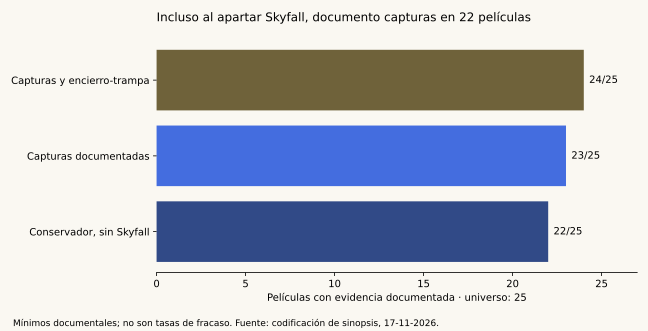

In [3]:
# visualizo cómo cambia el recuento al modificar el criterio
figura, eje = plt.subplots(figsize=(9, 4.6), facecolor='#faf8f2')
eje.set_facecolor('#faf8f2')
nombres = list(resultados)
valores = list(resultados.values())
eje.barh(nombres, valores, color=['#314a87', '#446ddf', '#6f623a'])
eje.set_xlim(0, 27)
eje.set_xticks([0, 5, 10, 15, 20, 25])
eje.set_xlabel('Películas con evidencia documentada · universo: 25')
eje.set_title('Incluso al apartar Skyfall, documento capturas en 22 películas', loc='left', pad=18)
for posicion, valor in enumerate(valores):
    eje.text(valor + .3, posicion, f'{valor}/25', va='center')
for borde in ['top', 'right', 'left']:
    eje.spines[borde].set_visible(False)
figura.text(.02, .015, 'Mínimos documentales; no son tasas de fracaso. Fuente: codificación de sinopsis, 17-11-2026.', fontsize=9)
figura.tight_layout(rect=(0, .05, 1, 1))
figura.savefig(raiz / 'exports/sensibilidad.svg', facecolor=figura.get_facecolor())
display(figura)
plt.close(figura)


La barra más corta conserva 22 películas. Puedo sostener que el cautiverio aparece de forma recurrente en las fuentes consultadas aunque aparte un caso contextual. No puedo sostener que todas esas escenas sean fallos de Bond. Las barras comparten películas y no son grupos independientes.

## Compruebo la cobertura por intérprete

Uso este desglose para comprobar que el hallazgo atraviesa las etapas de la saga. Cada intérprete tiene un número distinto de películas. No utilizo la tabla para declarar a uno mejor espía que otro.

In [4]:
# reviso mi cobertura sin convertir las diferencias de documentación en un ranking
for actor in dict.fromkeys(p['actor'] for p in peliculas):
    grupo = [p for p in peliculas if p['actor'] == actor]
    cantidad = sum(p['captura_documentada'] == '1' for p in grupo)
    print(f'{actor}: {cantidad} películas con captura documentada de {len(grupo)} estrenadas')


Sean Connery: 6 películas con captura documentada de 6 estrenadas
George Lazenby: 1 películas con captura documentada de 1 estrenadas
Roger Moore: 7 películas con captura documentada de 7 estrenadas
Timothy Dalton: 2 películas con captura documentada de 2 estrenadas
Pierce Brosnan: 4 películas con captura documentada de 4 estrenadas
Daniel Craig: 3 películas con captura documentada de 5 estrenadas


Encuentro al menos una película con captura en las seis etapas. No concluyo que una proporción menor sea mejor rendimiento: influyen la definición, el argumento y los casos que las sinopsis dejan sin detallar.

In [5]:
# compruebo los casos fronterizos y exporto resultados reproducibles
assert resultados['Conservador, sin Skyfall'] <= resultados['Capturas documentadas'] <= resultados['Capturas y encierro-trampa'] <= total
desconocidas = [p['titulo_original'] for p in peliculas if p['tipo'] == 'no_documentada']
trampas = [p['titulo_original'] for p in peliculas if p['tipo'] == 'encierro_trampa']
contextuales = [p['titulo_original'] for p in peliculas if p['acceso_voluntario'] == 'si']
assert desconocidas == ['Quantum of Solace']
assert trampas == ['No Time to Die']
assert contextuales == ['Skyfall']
resumen = {'categoria': 'EDA', 'universo': total, 'consulta': '2026-11-17', 'resultados': resultados, 'no_documentadas': desconocidas, 'encierro_trampa': trampas, 'casos_contextuales': contextuales}
(raiz / 'exports/resultados.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(resumen, ensure_ascii=False, indent=2))


{
  "categoria": "EDA",
  "universo": 25,
  "consulta": "2026-11-17",
  "resultados": {
    "Conservador, sin Skyfall": 22,
    "Capturas documentadas": 23,
    "Capturas y encierro-trampa": 24
  },
  "no_documentadas": [
    "Quantum of Solace"
  ],
  "encierro_trampa": [
    "No Time to Die"
  ],
  "casos_contextuales": [
    "Skyfall"
  ]
}


## Mi respuesta y sus límites

Documento cautiverios en casi toda la serie, pero **no puedo demostrar que Bond sea un pésimo espía**. El dato describe una situación del relato; la competencia exigiría evaluar objetivos, alternativas, riesgos y resultados. Tampoco comparo a Bond con agentes reales.

He realizado una sola codificación de fuentes secundarias, corroborada en casos concretos con materiales oficiales. No he hecho un visionado completo ni una segunda codificación independiente. Los porcentajes son mínimos documentados y dependen de mis criterios; no describen todas las escenas ni tasas por misión. Quantum of Solace queda sin prueba registrada, no declarado libre de capturas. La opción conservadora sólo aparta Skyfall; no acredita las intenciones de Bond en todas las demás escenas.

Conservo seis ejemplos de intervención de terceros en `data/raw/corroboraciones_y_ejemplos.csv`. No los trato como una muestra representativa, no calculo un porcentaje de rescates y no deduzco que Bond habría muerto con certeza en otra versión del argumento.

Mi aportación es un registro auditable de presencia documental y una comparación de definiciones. Para ampliarlo, necesitaría revisar las películas, fijar versiones y marcas de tiempo, y repetir la codificación con otra persona. Las referencias de cada registro y el libro de códigos permiten cuestionar y corregir mi lectura.
